### Taller de IA_II Corte III
A continuacion van a encontrar un dataset sobre un censo que se realizó en estados unidos y hay diferentes tipos de variables para determinar si una persona va a ganar o no más de 50000 dólares anuales. 

In [371]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo     # Importamos el dataset de la librería ucimlrepo
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, ConfusionMatrixDisplay



archivo = "census_income.csv"           # Creamos un dataset local para no tener que descargarlo cada vez que ejecutemos el código

if os.path.exists(archivo):             # Si el archivo existe, lo cargamos desde el disco
    df = pd.read_csv(archivo)               
else:                                   # Si el archivo no existe, lo descargamos y guardamos
    census_income = fetch_ucirepo(id=20)
    df = census_income.data.original
    df.to_csv(archivo, index=False)     # Guarda la copia

#X = df.drop(columns=["income"])         # Separamos el dataset en variables predictoras y variable objetivo
#y = df["income"]

### ETL & EDA

In [372]:
df.shape        # Mostramos la cantidad de registros y variables del dataset

(48842, 15)

In [373]:
df.info()       # Mostramos información del dataset

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [374]:
df.isnull().sum()       # Contamos la cantidad de valores nulos por columna

age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

In [375]:
(df == "?").sum()       # Contamos la cantidad de valores "?" por columna

age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64

In [376]:
df["income"].unique()           # Mostramos las categorías de la variable objetivo 

<StringArray>
['<=50K', '>50K', '<=50K.', '>50K.']
Length: 4, dtype: str

In [377]:
df["income"].value_counts()     # Contamos la cantidad de registros por categoría de la variable objetivo

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

In [378]:
""" Validamos la cantidad de registros por categoría de las variables categóricas
para identificar posibles errores de tipeo o inconsistencias en los nombres de las categorías.  """

columnas_texto = df.select_dtypes(exclude="number").columns

for col in columnas_texto:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- workclass ---
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
?                    1836
Self-emp-inc         1695
Federal-gov          1432
NaN                   963
Without-pay            21
Never-worked           10
Name: count, dtype: int64

--- education ---
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
Name: count, dtype: int64

--- marital-status ---
marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Married-AF-spouse           37
Name: count, dtype: in

In [379]:
# Validadmos si existen registros que solo contienen caracteres especiales en las variables de tipo texto

for col in columnas_texto:
    sospechosos = df[col][df[col].str.fullmatch(r"[^A-Za-z0-9]*", na=False)]
    if not sospechosos.empty:
        print(col, sospechosos.value_counts().to_dict())

workclass {'?': 1836}
occupation {'?': 1843}
native-country {'?': 583}


In [380]:
""" Teniendo en cuenta lo anterior limpiamos el dataset reemplazando los valores "?" por NaN 
y eliminando los registros que contienen caracteres especiales en las variables de tipo texto """

for col in columnas_texto:
    df[col] = df[col].str.strip()   # Eliminamos espacios en blanco al inicio y al final de los registros

df = df.replace("?", np.nan)        # Reemplazamos los valores "?" por NaN   

for col in ["workclass", "occupation", "native-country"]:
    df[col] = df[col].fillna("Desconocido")   # Reemplazamos los valores NaN por "Desconocido" en las variables categóricas

df["income"] = df["income"].str.replace(".", "", regex=False)   # Eliminamos el punto de los registros de la variable objetivo

print(df.isnull().sum())       # Contamos la cantidad de valores nulos por columna
print(df["income"].value_counts())     # Contamos la cantidad de registros por categoría de la variable objetivo

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [381]:
df.head(20)     # Mostramos los primeros 20 registros del dataset

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
8,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
9,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K


In [382]:
df["income"] =  df["income"].replace({"<=50K": 0, ">50K": 1}).astype(int)   # Reemplazamos las categorías de la variable objetivo por valores numéricos

<Axes: >

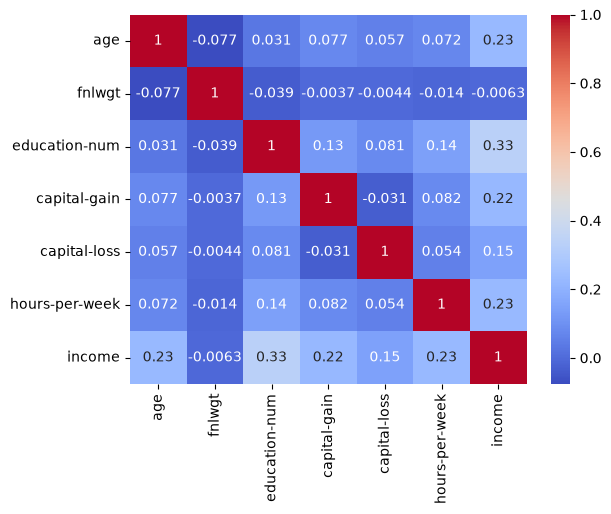

In [383]:
# Mostramos la correlación entre las variables numéricas del dataset

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

In [384]:
# Eliminamos la variable "fnlwgt" ya que no aporta información relevante para el análisis y puede generar ruido en los modelos de machine learning

df = df.drop("fnlwgt", axis=1)

In [385]:
"""para cada variable de texto, agrupa a las personas por categoría y 
nos dice qué porcentaje de cada grupo gana más de 50K y cuántas personas hay. 
Así vemos qué categorías separan mejor a los que ganan más de los que ganan menos."""

for col in df.select_dtypes(exclude="number").columns:
    print(df.groupby(col)["income"].agg(["mean", "count"])
            .sort_values("mean", ascending=False).round(2), "\n")

                  mean  count
workclass                    
Self-emp-inc      0.55   1695
Federal-gov       0.39   1432
Local-gov         0.30   3136
Self-emp-not-inc  0.28   3862
State-gov         0.27   1981
Private           0.22  33906
Without-pay       0.10     21
Desconocido       0.09   2799
Never-worked      0.00     10 

              mean  count
education                
Prof-school   0.74    834
Doctorate     0.73    594
Masters       0.55   2657
Bachelors     0.41   8025
Assoc-acdm    0.26   1601
Assoc-voc     0.25   2061
Some-college  0.19  10878
HS-grad       0.16  15784
12th          0.07    657
7th-8th       0.06    955
10th          0.06   1389
9th           0.05    756
5th-6th       0.05    509
11th          0.05   1812
1st-4th       0.03    247
Preschool     0.01     83 

                       mean  count
marital-status                    
Married-civ-spouse     0.45  22379
Married-AF-spouse      0.38     37
Divorced               0.10   6633
Married-spouse-absent  

In [386]:
df = df.drop("education", axis=1)       # Eliminamos la variable "education" ya que no aporta información relevante para el análisis y puede generar ruido en los modelos de machine learning

In [387]:
"""convierte cada categoría en una pregunta de sí/no, mide qué tanto se relaciona cada respuesta 
con ganar >50K y te muestra las 10 relaciones más fuertes, tanto positivas como negativas."""

dummies = pd.get_dummies(df.select_dtypes(exclude="number"), dtype=int)
print(dummies.corrwith(df["income"]).sort_values(key=abs, ascending=False).head(30).round(3))

marital-status_Married-civ-spouse       0.446
relationship_Husband                    0.404
marital-status_Never-married           -0.319
relationship_Own-child                 -0.226
sex_Male                                0.215
sex_Female                             -0.215
occupation_Exec-managerial              0.211
relationship_Not-in-family             -0.190
occupation_Prof-specialty               0.189
occupation_Other-service               -0.155
relationship_Unmarried                 -0.144
workclass_Self-emp-inc                  0.140
marital-status_Divorced                -0.128
relationship_Wife                       0.120
race_Black                             -0.090
occupation_Adm-clerical                -0.086
relationship_Other-relative            -0.086
occupation_Handlers-cleaners           -0.085
occupation_Desconocido                 -0.084
race_White                              0.084
workclass_Desconocido                  -0.084
workclass_Private                 

In [388]:
dummies.head(20)    # Verificamos que las variables categóricas se hayan convertido correctamente en variables dummy

,workclass_Desconocido,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Divorced,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
6,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
8,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
9,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


### MODELOS

In [389]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   education-num   48842 non-null  int64
 3   marital-status  48842 non-null  str  
 4   occupation      48842 non-null  str  
 5   relationship    48842 non-null  str  
 6   race            48842 non-null  str  
 7   sex             48842 non-null  str  
 8   capital-gain    48842 non-null  int64
 9   capital-loss    48842 non-null  int64
 10  hours-per-week  48842 non-null  int64
 11  native-country  48842 non-null  str  
 12  income          48842 non-null  int64
dtypes: int64(6), str(7)
memory usage: 4.8 MB


In [390]:
# Dividimos el dataset en variables predictoras y variable objetivo
X = pd.get_dummies(df.drop(columns=["income"]), dtype=int)
y = df["income"]

In [391]:
# Dividimos el dataset en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [392]:
arbol = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)    # creamos el modelo de árbol de decisión
arbol.fit(X_train, y_train)                                                       # entrenamos el modelo

DecisionTreeClassifier(max_depth=5, random_state=42)

In [393]:
y_pred = arbol.predict(X_test)                  # Hacemos predicciones sobre el conjunto de prueba
accuracy = accuracy_score(y_test, y_pred)       # Calculamos la precisión del modelo
print(f"Precisión del modelo: {accuracy:.2f}")  # Mostramos la precisión del modelo

Precisión del modelo: 0.85


marital-status_Married-civ-spouse    0.477
education-num                        0.228
capital-gain                         0.216
capital-loss                         0.048
hours-per-week                       0.019
age                                  0.010
dtype: float64


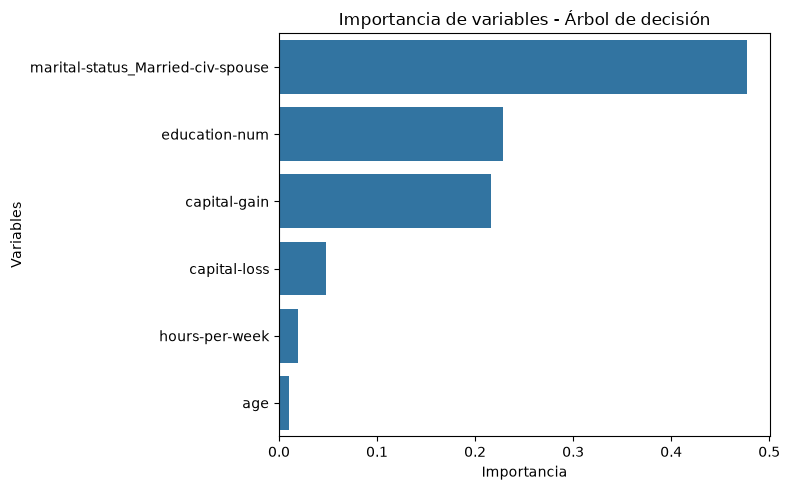

In [394]:
# Graficamos la importancia de caracteristicas

# Unimos el nombre e importancia en una sola tabla
imp = pd.Series(arbol.feature_importances_, index=X.columns)

# Nos quedamos con las que importan (> 0) y ordenarlas
imp = imp[imp > 0.005].sort_values(ascending=False).head(15)
print(imp.round(3))

# Gráfico
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Importancia de variables - Árbol de decisión")
plt.xlabel("Importancia")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.90      7414
        >50K       0.76      0.54      0.63      2355

    accuracy                           0.85      9769
   macro avg       0.81      0.74      0.77      9769
weighted avg       0.84      0.85      0.84      9769

ROC-AUC: 0.883


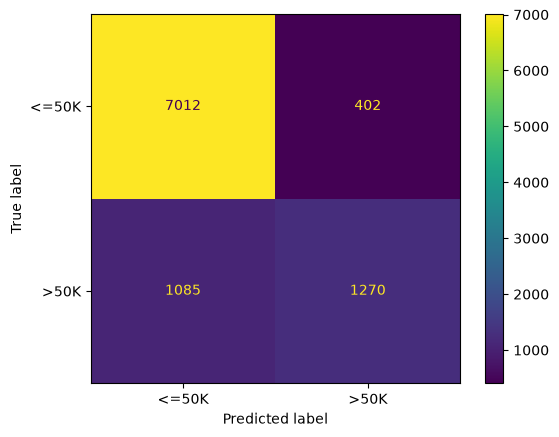

In [395]:

y_pred = arbol.predict(X_test)
y_prob = arbol.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["<=50K", ">50K"])
plt.show()